In [13]:
from pathlib import Path
import joblib

import numpy as np
import pandas as pd

In [7]:
model_path = Path("../models/baseline_model.joblib")

baseline_model = joblib.load(model_path)

print("Baseline model loaded successfully!")

Baseline model loaded successfully!


In [8]:
print(baseline_model)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical', StandardScaler(),
                                                  ['INT_SQFT', 'DIST_MAINROAD',
                                                   'N_BEDROOM', 'N_BATHROOM',
                                                   'N_ROOM', 'QS_ROOMS',
                                                   'QS_BATHROOM', 'QS_BEDROOM',
                                                   'QS_OVERALL', 'COMMIS']),
                                                 ('categorical',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['AREA', 'SALE_COND',
                                                   'PARK_FACIL', 'BUILDTYPE',
                                                   'UTILITY_AVAIL', 'STREET',
                                                   'MZZONE'])])),
                ('model', LinearRegression())])


In [16]:
data_path = Path("../data/processed/chennai_house_price_prediction_cleaned.csv")

df = pd.read_csv(data_path)

print("Dataset loaded:", df.shape)

Dataset loaded: (7109, 19)


In [17]:
X = df.drop(columns=["SALES_PRICE"])
y = df["SALES_PRICE"]

In [18]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [19]:
X_fit, X_val, y_fit, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42)

print("Model fitting data:", X_fit.shape)
print("Validation data:", X_val.shape)

Model fitting data: (4549, 18)
Validation data: (1138, 18)


In [23]:
from sklearn.base import clone

selection_model = clone(baseline_model)

selection_model.fit(X_fit, y_fit)

print("Feature selection model trained successfully!")

Feature selection model trained successfully!


In [24]:
permutation_results = permutation_importance(
    selection_model,
    X_val,
    y_val,
    scoring="r2",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

feature_importance_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance_Mean": permutation_results.importances_mean,
    "Importance_Std": permutation_results.importances_std
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance_Mean",
    ascending=False
).reset_index(drop=True)

display(feature_importance_df)

,Feature,Importance_Mean,Importance_Std
0,BUILDTYPE,0.580328,0.017468
1,INT_SQFT,0.433263,0.010470
2,AREA,0.292579,0.005670
3,MZZONE,0.107539,0.003849
4,PARK_FACIL,0.036407,0.002412
5,STREET,0.030182,0.001233
6,SALE_COND,0.006182,0.000679
7,N_ROOM,0.005661,0.000727
8,N_BEDROOM,0.005158,0.000703
9,COMMIS,0.004763,0.000752


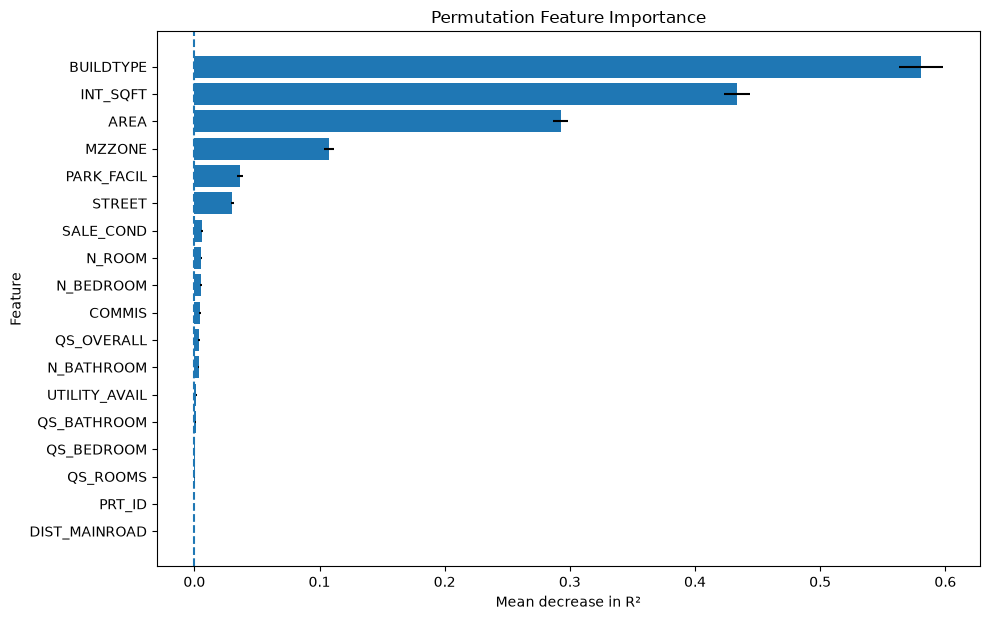

In [26]:
import matplotlib.pyplot as plt
plot_df = feature_importance_df.sort_values(
    by="Importance_Mean",
    ascending=True
)

plt.figure(figsize=(10, max(6, len(plot_df) * 0.35)))

plt.barh(
    plot_df["Feature"],
    plot_df["Importance_Mean"],
    xerr=plot_df["Importance_Std"]
)

plt.axvline(x=0, linestyle="--")

plt.xlabel("Mean decrease in R²")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance")

plt.tight_layout()
plt.show()

In [28]:
low_importance_features = feature_importance_df.loc[
    feature_importance_df["Importance_Mean"] <= 0.001,
    ["Feature", "Importance_Mean", "Importance_Std"]
]

display(low_importance_features)

print(
    "Number of features below threshold:",
    len(low_importance_features)
)

,Feature,Importance_Mean,Importance_Std
13,QS_BATHROOM,0.000935,0.000228
14,QS_BEDROOM,0.000661,0.000234
15,QS_ROOMS,0.000254,0.000242
16,PRT_ID,0.000000,0.000000
17,DIST_MAINROAD,-0.000007,0.000006


Number of features below threshold: 5


In [38]:
# Define the features to remove
features_to_remove = [
    "QS_BATHROOM",
    "QS_BEDROOM",
    "QS_ROOMS",
    "PRT_ID",
    "DIST_MAINROAD"
]

existing_features_to_remove = [
    col for col in features_to_remove
    if col in X_train.columns
]

selected_features = [
    col for col in X_train.columns
    if col not in existing_features_to_remove
]

X_train_selected = X_train[selected_features]

print("Original feature count:", X_train.shape[1])
print("Removed features:", existing_features_to_remove)
print("Selected feature count:", X_train_selected.shape[1])

Original feature count: 18
Removed features: ['QS_BATHROOM', 'QS_BEDROOM', 'QS_ROOMS', 'PRT_ID', 'DIST_MAINROAD']
Selected feature count: 13


In [ ]:
# Update the numerical and categorical feature lists
numerical_features = [
    "INT_SQFT",
    "DIST_MAINROAD",
    "N_BEDROOM",
    "N_BATHROOM",
    "N_ROOM",
    "QS_ROOMS",
    "QS_BATHROOM",
    "QS_BEDROOM",
    "QS_OVERALL",
    "COMMIS"
]

categorical_features = [
    "AREA",
    "SALE_COND",
    "PARK_FACIL",
    "BUILDTYPE",
    "UTILITY_AVAIL",
    "STREET",
    "MZZONE"
]

numerical_features = [
    col for col in numerical_features
    if col not in features_to_remove
]

categorical_features = [
    col for col in categorical_features
    if col not in features_to_remove
]

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['INT_SQFT', 'N_BEDROOM', 'N_BATHROOM', 'N_ROOM', 'QS_OVERALL', 'COMMIS']
Categorical features: ['AREA', 'SALE_COND', 'PARK_FACIL', 'BUILDTYPE', 'UTILITY_AVAIL', 'STREET', 'MZZONE']


In [50]:
# Rebuild the preprocessing pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor_selected = ColumnTransformer(
    transformers=[
        (
            "numerical",
            StandardScaler(),
            numerical_features
        ),
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ],
    remainder="drop"
)

In [53]:
# Build the reduced-feature model
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

selected_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor_selected),
        ("model", LinearRegression())
    ]
)

print("Reduced-feature pipeline created successfully!")

Reduced-feature pipeline created successfully!


In [54]:
# Remove the features from your datasets
selected_features = [
    col for col in X_fit.columns
    if col not in features_to_remove
]

X_fit_selected = X_fit[selected_features]
X_val_selected = X_val[selected_features]

print("Original feature count:", X_fit.shape[1])
print("Selected feature count:", X_fit_selected.shape[1])

print("Training shape:", X_fit_selected.shape)
print("Validation shape:", X_val_selected.shape)

Original feature count: 18
Selected feature count: 13
Training shape: (4549, 13)
Validation shape: (1138, 13)


In [55]:
# Train the reduced-feature model
selected_model.fit(
    X_fit_selected,
    y_fit
)

print("Reduced-feature model trained successfully!")

Reduced-feature model trained successfully!


In [56]:
import numpy as np

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

y_val_pred = selected_model.predict(X_val_selected)

selected_r2 = r2_score(y_val, y_val_pred)

selected_mae = mean_absolute_error(
    y_val,
    y_val_pred
)

selected_rmse = np.sqrt(
    mean_squared_error(y_val, y_val_pred)
)

print("Reduced-Feature Model Performance")
print("-" * 40)
print(f"R² Score: {selected_r2:.4f}")
print(f"MAE:      {selected_mae:.2f}")
print(f"RMSE:     {selected_rmse:.2f}")

Reduced-Feature Model Performance
----------------------------------------
R² Score: 0.9529
MAE:      609229.99
RMSE:     794362.50


In [57]:
y_val_baseline = selection_model.predict(X_val)

comparison_df = pd.DataFrame({
    "Model": [
        "Baseline Model (All Features)",
        "Reduced-Feature Model"
    ],
    "R2_Score": [
        r2_score(y_val, y_val_baseline),
        selected_r2
    ],
    "MAE": [
        mean_absolute_error(y_val, y_val_baseline),
        selected_mae
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_val, y_val_baseline)),
        selected_rmse
    ],
    "Feature_Count": [
        X_fit.shape[1],
        X_fit_selected.shape[1]
    ]
})

display(comparison_df)

,Model,R2_Score,MAE,RMSE,Feature_Count
0,Baseline Model (All Features),0.952898,609708.310227,794717.260225,18
1,Reduced-Feature Model,0.952940,609229.992056,794362.501466,13


In [58]:
# Save the selected features
output_path = Path("../models/selected_features.joblib")

output_path.parent.mkdir(
    parents=True,
    exist_ok=True
)

joblib.dump(
    selected_features,
    output_path
)

print("Selected features saved successfully!")
print("Location:", output_path)
print("Number of features:", len(selected_features))

Selected features saved successfully!
Location: ..\models\selected_features.joblib
Number of features: 13


In [59]:
# Save the reduced-feature model

model_path = Path("../models/selected_model.joblib")

joblib.dump(
    selected_model,
    model_path
)

print("Reduced-feature model saved successfully!")
print("Location:", model_path)

Reduced-feature model saved successfully!
Location: ..\models\selected_model.joblib
